In [1]:
# ============================================================================
# IEEE ACCESS PAPER: HiENBERT - Hybrid Indic-English BERT for Multi-Task 
# Complaint Classification - OPTIMIZED VERSION
# ============================================================================
# CELL 1: IMPORTS AND SYSTEM SETUP - OPTIMIZED
# ============================================================================

import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
import random
from datetime import datetime
import time

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast

# Transformers
from transformers import (
    AutoTokenizer, 
    AutoModel,
    get_cosine_schedule_with_warmup,
    get_linear_schedule_with_warmup
)

# Scikit-learn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score,
    classification_report, 
    confusion_matrix,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef
)

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = True

set_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    torch.backends.cudnn.benchmark = True
print(f"Using device: {device}")
print(f"{'='*80}\n")


SYSTEM INFORMATION
PyTorch version: 2.6.0+cu126
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070
CUDA memory: 8.59 GB
Using device: cuda



In [ ]:
# ============================================================================
# CELL 2: OPTIMIZED CONFIGURATION - FASTER TRAINING
# ============================================================================

class Config:
    """Optimized configuration settings for HiENBERT training"""
    
    # =========================================================================
    # BASE MODEL
    # =========================================================================
    BASE_MODEL = 'xlm-roberta'
    XLMBERT_PATH = "xlm-roberta-base"
    
    # =========================================================================
    # PROJECT ROOT DIRECTORY
    # =========================================================================
    PROJECT_DIR = os.getcwd()
    
    # =========================================================================
    # INPUT DATASET DIRECTORY
    # =========================================================================
    DATA_DIR = os.path.join(PROJECT_DIR, "Synthetic_Dataset")
    TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
    DEV_PATH = os.path.join(DATA_DIR, "dev.csv")
    TEST_PATH = os.path.join(DATA_DIR, "test.csv")
    
    # =========================================================================
    # OUTPUT DIRECTORY
    # =========================================================================
    BASE_DIR = os.path.join(PROJECT_DIR, "hienbert_results_optimized")
    MODEL_DIR = os.path.join(BASE_DIR, "models")
    VISUALIZATION_DIR = os.path.join(BASE_DIR, "visualizations")
    LOG_DIR = os.path.join(BASE_DIR, "logs")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")
    CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
    SHAP_DIR = os.path.join(BASE_DIR, "shap_explanations")
    
    for dir_path in [BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, LOG_DIR,
                     RESULTS_DIR, CHECKPOINT_DIR, SHAP_DIR]:
        os.makedirs(dir_path, exist_ok=True)
    
    # =========================================================================
    # OPTIMIZED TRAINING PARAMETERS - FASTER
    # =========================================================================
    MAX_LENGTH = 128
    BATCH_SIZE = 64  # Increased for faster training
    EPOCHS = 10      # Reduced epochs - early stopping will handle
    LEARNING_RATE = 3e-5  # Slightly higher for faster convergence
    DROPOUT = 0.2
    WEIGHT_DECAY = 0.01
    GRADIENT_ACCUMULATION_STEPS = 2  # Effective batch size = 64 * 2 = 128
    WARMUP_RATIO = 0.1
    
    # =========================================================================
    # OPTIMIZED TRAINING SETTINGS
    # =========================================================================
    USE_AMP = True
    NUM_WORKERS = 4  # For faster data loading
    PIN_MEMORY = True
    
    # =========================================================================
    # DEVICE
    # =========================================================================
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    SEED = 42
    
    # =========================================================================
    # HUGGING FACE TOKEN
    # =========================================================================
    HF_TOKEN = os.getenv("HF_TOKEN")


def get_model_path():
    return Config.XLMBERT_PATH


print("=" * 80)
print("OPTIMIZED HIENBERT CONFIGURATION")
print("=" * 80)
print(f"\n[BATCH SIZE] {Config.BATCH_SIZE} (Effective: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS})")
print(f"[EPOCHS] {Config.EPOCHS}")
print(f"[LEARNING RATE] {Config.LEARNING_RATE}")
print(f"[NUM WORKERS] {Config.NUM_WORKERS}")
print(f"[DEVICE] {Config.DEVICE}")
print("=" * 80)

OPTIMIZED HIENBERT CONFIGURATION

[BATCH SIZE] 64 (Effective: 128)
[EPOCHS] 10
[LEARNING RATE] 3e-05
[NUM WORKERS] 4
[DEVICE] cuda


In [3]:
# ============================================================================
# CELL 3: OPTIMIZED DATA LOADING
# ============================================================================

class OptimizedDataLoader:
    """Load and analyze balanced dataset - OPTIMIZED"""
    
    def __init__(self):
        self.train_df = None
        self.dev_df = None
        self.test_df = None
    
    def load_data(self):
        print("Loading datasets...")
        self.train_df = pd.read_csv(Config.TRAIN_PATH)
        self.dev_df = pd.read_csv(Config.DEV_PATH)
        self.test_df = pd.read_csv(Config.TEST_PATH)
        print(f"Train: {len(self.train_df)}, Dev: {len(self.dev_df)}, Test: {len(self.test_df)}")
        return self.train_df, self.dev_df, self.test_df
    
    def analyze_distribution(self, df, label_col, title=""):
        class_counts = df[label_col].value_counts()
        class_percentages = df[label_col].value_counts(normalize=True) * 100
        print(f"\n{'='*60}")
        print(f"Class Distribution - {title}")
        print(f"{'='*60}")
        for cls, count in class_counts.items():
            print(f"  {cls}: {count} ({class_percentages[cls]:.2f}%)")
        return class_counts
    
    def analyze_all(self):
        self.load_data()
        print("\n" + "="*80)
        print("DATASET ANALYSIS")
        print("="*80)
        self.analyze_distribution(self.train_df, 'primary_category', 'Primary Categories')
        self.analyze_distribution(self.train_df, 'Severity', 'Severity')
        return self.train_df, self.dev_df, self.test_df

# Load data
data_loader = OptimizedDataLoader()
train_df, dev_df, test_df = data_loader.load_data()

Loading datasets...
Train: 10500, Dev: 2250, Test: 2250


In [4]:
# ============================================================================
# CELL 4: OPTIMIZED DATA PREPROCESSING
# ============================================================================

class OptimizedPreprocessor:
    """Optimized data preprocessing with efficient text handling"""
    
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
        self.column_mapping = {
            'primary_category': 'category_primary',
            'secondary_category': 'category_secondary',
            'Severity': 'severity',
            'Complaint_Title': 'complaint_title',
            'Text_en': 'text_en',
            'Text_hi': 'Hindi',
            'Text_hinglish': 'Hinglish'
        }
    
    def rename_columns(self, df):
        rename_dict = {k: v for k, v in self.column_mapping.items() if k in df.columns}
        if rename_dict:
            df = df.rename(columns=rename_dict)
        return df
    
    def preprocess_text(self, df):
        df = self.rename_columns(df)
        
        # Fill NaN values efficiently
        text_cols = ['complaint_title', 'text_en', 'Hindi', 'Hinglish']
        for col in text_cols:
            if col in df.columns:
                df[col] = df[col].fillna('').astype(str)
        
        # Combine text efficiently
        available_cols = [col for col in text_cols if col in df.columns]
        if available_cols:
            df["text"] = df[available_cols].agg(" ".join, axis=1)
            df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
        
        df = df.dropna(subset=["category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def prepare_labels(self, train_df, dev_df, test_df):
        print("\nPreparing labels...")
        
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['severity'])
        
        print(f"Primary: {len(self.le_primary.classes_)}, "
              f"Subcat: {len(self.le_subcat.classes_)}, "
              f"Severity: {len(self.le_severity.classes_)}")
        
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["severity"])
            df["sentiment_score"] = 0.0
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        print("\nPreprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        
        print(f"\nFinal: Train {len(train_df)}, Dev {len(dev_df)}, Test {len(test_df)}")
        return train_df, dev_df, test_df

# Process data
preprocessor = OptimizedPreprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)
print("\n✅ Data preprocessing completed")


Preprocessing text...

Preparing labels...
Primary: 8, Subcat: 24, Severity: 3

Final: Train 10500, Dev 2250, Test 2250

✅ Data preprocessing completed


In [5]:
# ============================================================================
# CELL 5: OPTIMIZED DATASET CLASS
# ============================================================================

class OptimizedComplaintDataset(Dataset):
    """Optimized dataset with efficient tokenization"""
    
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].astype(str).tolist()
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }


def create_optimized_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create optimized dataloaders with multiple workers"""
    print("\nCreating optimized dataloaders...")
    
    train_dataset = OptimizedComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
    dev_dataset = OptimizedComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
    test_dataset = OptimizedComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)
    
    train_loader = DataLoader(
        train_dataset,
        batch_size=Config.BATCH_SIZE,
        shuffle=True,
        num_workers=Config.NUM_WORKERS,
        pin_memory=Config.PIN_MEMORY,
        drop_last=False,
        prefetch_factor=4
    )
    
    dev_loader = DataLoader(
        dev_dataset,
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False,
        num_workers=Config.NUM_WORKERS // 2,
        pin_memory=Config.PIN_MEMORY
    )
    
    test_loader = DataLoader(
        test_dataset,
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False,
        num_workers=Config.NUM_WORKERS // 2,
        pin_memory=Config.PIN_MEMORY
    )
    
    print(f"Train batches: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")
    return train_loader, dev_loader, test_loader

print("✅ Dataset class defined")

✅ Dataset class defined


In [6]:
# ============================================================================
# CELL 6: OPTIMIZED HIENBERT MODEL
# ============================================================================

class OptimizedHiEnBERT(nn.Module):
    """Optimized HiENBERT model with efficient architecture"""
    
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        
        # Single shared layer for efficiency
        self.shared = nn.Linear(hidden_size, hidden_size)
        self.gelu = nn.GELU()
        
        # Task-specific heads
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity, self.shared]:
            if hasattr(module, 'weight'):
                nn.init.xavier_uniform_(module.weight)
            if hasattr(module, 'bias') and module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        # Shared representation
        x = self.gelu(self.shared(cls_embedding))
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def get_embeddings(self, input_ids, attention_mask):
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]

In [7]:
# ============================================================================
# CELL 7: LOAD BASE MODEL
# ============================================================================

def load_base_model():
    model_path = get_model_path()
    print(f"Loading base model: {model_path}")
    
    tokenizer = AutoTokenizer.from_pretrained(
        model_path,
        token=Config.HF_TOKEN,
        use_fast=True  # Fast tokenizer for speed
    )
    
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    
    base_model = AutoModel.from_pretrained(
        model_path,
        token=Config.HF_TOKEN
    )
    
    print(f"Vocab size: {tokenizer.vocab_size}, Hidden: {base_model.config.hidden_size}")
    return base_model, tokenizer

# Load model
base_model, tokenizer = load_base_model()
base_model = base_model.to(Config.DEVICE)

# Create optimized model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = OptimizedHiEnBERT(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

print(f"\n✅ Model loaded: {sum(p.numel() for p in model.parameters()):,} parameters")

Loading base model: xlm-roberta-base


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15298.98it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vocab size: 250002, Hidden: 768

✅ Model loaded: 278,661,155 parameters


In [8]:
# ============================================================================
# CELL 8: FIXED OPTIMIZED TRAINING FUNCTIONS
# ============================================================================

class MultiTaskLoss(nn.Module):
    """Efficient multi-task loss"""
    def __init__(self):
        super().__init__()
        self.primary_loss = nn.CrossEntropyLoss()
        self.subcat_loss = nn.CrossEntropyLoss()
        self.severity_loss = nn.CrossEntropyLoss()
        
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = 0.5
    
    def forward(self, p1, p2, p3, y1, y2, y3):
        loss1 = self.primary_loss(p1, y1)
        loss2 = self.subcat_loss(p2, y2)
        loss3 = self.severity_loss(p3, y3)
        
        total = self.primary_weight * loss1 + self.subcat_weight * loss2 + self.severity_weight * loss3
        return total, {'primary': loss1.item(), 'subcat': loss2.item(), 'severity': loss3.item()}

criterion = MultiTaskLoss()


class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
    
    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return False
        
        if self.mode == 'max':
            improvement = score - self.best_score > self.min_delta
        else:
            improvement = self.best_score - score > self.min_delta
        
        if improvement:
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop


def train_epoch_optimized(model, dataloader, optimizer, scheduler, criterion, device, scaler=None):
    """FIXED: Optimized training loop - properly handles gradient accumulation"""
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []
    task_losses = {'primary': 0, 'subcat': 0, 'severity': 0}
    
    optimizer.zero_grad()  # Initialize with zero grad
    
    progress_bar = tqdm(dataloader, desc='Training', leave=False)
    
    for batch_idx, batch in enumerate(progress_bar):
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        y_primary = batch['primary'].to(device, non_blocking=True)
        y_subcat = batch['subcat'].to(device, non_blocking=True)
        y_severity = batch['severity'].to(device, non_blocking=True)
        sentiment = batch['sentiment'].to(device, non_blocking=True)
        
        # Forward pass with mixed precision
        if scaler is not None:
            with autocast():
                p1, p2, p3 = model(input_ids, attention_mask, sentiment)
                loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        else:
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        
        # Normalize loss for gradient accumulation
        loss = loss / Config.GRADIENT_ACCUMULATION_STEPS
        
        # Backward pass
        if scaler is not None:
            scaler.scale(loss).backward()
        else:
            loss.backward()
        
        # Update weights only after accumulation steps
        if (batch_idx + 1) % Config.GRADIENT_ACCUMULATION_STEPS == 0:
            if scaler is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
        
        total_loss += loss.item() * Config.GRADIENT_ACCUMULATION_STEPS
        
        for key in task_losses:
            task_losses[key] += loss_dict.get(key, 0)
        
        preds = torch.argmax(p1, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_primary.cpu().numpy())
        
        # Update progress bar with current batch accuracy
        current_acc = accuracy_score(all_labels[-input_ids.size(0):], preds.cpu().numpy())
        progress_bar.set_postfix({
            'loss': f'{loss.item() * Config.GRADIENT_ACCUMULATION_STEPS:.3f}',
            'acc': f'{current_acc:.3f}',
            'batch': f'{batch_idx+1}/{len(dataloader)}'
        })
    
    avg_loss = total_loss / len(dataloader)
    acc = accuracy_score(all_labels, all_preds)
    bal_acc = balanced_accuracy_score(all_labels, all_preds)
    
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, acc, bal_acc, task_losses


def evaluate_optimized(model, dataloader, device, return_predictions=False):
    """Fixed optimized evaluation"""
    model.eval()
    all_preds = []
    all_labels = []
    all_confidences = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            sentiment = batch['sentiment'].to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask, sentiment)
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics

In [9]:
# ============================================================================
# CELL 9: FIXED - CREATE OPTIMIZED DATALOADERS
# ============================================================================

# FIRST, let's test with a smaller batch size to ensure it works
# Override Config for testing
Config.BATCH_SIZE = 32  # Reduce batch size for stability
Config.GRADIENT_ACCUMULATION_STEPS = 1  # Start with no accumulation
Config.NUM_WORKERS = 0  # Use 0 for debugging (will show errors)

print(f"USING: Batch Size={Config.BATCH_SIZE}, Accumulation={Config.GRADIENT_ACCUMULATION_STEPS}, Workers={Config.NUM_WORKERS}")

# FIXED: Create dataloaders with conditional prefetch_factor
def create_fixed_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create dataloaders with proper handling of prefetch_factor"""
    print("\nCreating optimized dataloaders...")
    
    train_dataset = OptimizedComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
    dev_dataset = OptimizedComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
    test_dataset = OptimizedComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)
    
    # Common DataLoader arguments
    common_args = {
        'batch_size': Config.BATCH_SIZE,
        'shuffle': True,
        'num_workers': Config.NUM_WORKERS,
        'pin_memory': Config.PIN_MEMORY,
        'drop_last': False
    }
    
    # Only add prefetch_factor if num_workers > 0
    if Config.NUM_WORKERS > 0:
        common_args['prefetch_factor'] = 4
    
    train_loader = DataLoader(train_dataset, **common_args)
    
    # Validation loader
    val_args = {
        'batch_size': Config.BATCH_SIZE * 2,
        'shuffle': False,
        'num_workers': Config.NUM_WORKERS // 2 if Config.NUM_WORKERS > 1 else 0,
        'pin_memory': Config.PIN_MEMORY
    }
    if Config.NUM_WORKERS > 1:
        val_args['prefetch_factor'] = 2
    
    dev_loader = DataLoader(dev_dataset, **val_args)
    test_loader = DataLoader(test_dataset, **val_args)
    
    print(f"Train batches: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")
    return train_loader, dev_loader, test_loader

# Create dataloaders
train_loader, dev_loader, test_loader = create_fixed_dataloaders(
    train_df, dev_df, test_df, tokenizer
)

# Test one batch to ensure it works
print("\nTesting data loader...")
test_batch = next(iter(train_loader))
print(f"Input shape: {test_batch['input_ids'].shape}")
print(f"Labels: {test_batch['primary'].shape}")
print("✅ Data loader working!")

# Setup optimizer
optimizer = AdamW(
    model.parameters(),
    lr=Config.LEARNING_RATE,
    weight_decay=Config.WEIGHT_DECAY,
    betas=(0.9, 0.999),
    eps=1e-8
)

total_steps = len(train_loader) * Config.EPOCHS // Config.GRADIENT_ACCUMULATION_STEPS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps
)

scaler = GradScaler() if Config.USE_AMP and torch.cuda.is_available() else None
early_stopping = EarlyStopping(patience=5, mode='max')

print(f"\nTraining setup:")
print(f"  Total batches per epoch: {len(train_loader)}")
print(f"  Total steps: {total_steps}")
print(f"  Warmup steps: {int(Config.WARMUP_RATIO * total_steps)}")
print(f"  Effective batch size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"  Mixed precision: {scaler is not None}")

USING: Batch Size=32, Accumulation=1, Workers=0

Creating optimized dataloaders...
Train batches: 329, Dev: 36, Test: 36

Testing data loader...
Input shape: torch.Size([32, 128])
Labels: torch.Size([32])
✅ Data loader working!

Training setup:
  Total batches per epoch: 329
  Total steps: 3290
  Warmup steps: 329
  Effective batch size: 32
  Mixed precision: True


In [10]:
# ============================================================================
# CELL 10: FIXED TRAINING LOOP
# ============================================================================

train_history = []
val_history = []
best_val_f1 = 0
best_val_balanced_acc = 0

print("\n" + "="*80)
print(f"TRAINING HIENBERT WITH {Config.BASE_MODEL.upper()}")
print("="*80 + "\n")

start_time = time.time()

# Try a single batch first to test
print("\nTesting forward pass...")
test_batch = next(iter(train_loader))
input_ids = test_batch['input_ids'].to(Config.DEVICE)
attention_mask = test_batch['attention_mask'].to(Config.DEVICE)
sentiment = test_batch['sentiment'].to(Config.DEVICE)
p1, p2, p3 = model(input_ids, attention_mask, sentiment)
print(f"Output shapes: {p1.shape}, {p2.shape}, {p3.shape}")
print("✅ Forward pass working!")

# Now train
for epoch in range(Config.EPOCHS):
    epoch_start = time.time()
    print(f"\nEpoch {epoch+1}/{Config.EPOCHS}")
    print("-"*50)
    
    # Training
    try:
        train_loss, train_acc, train_bal_acc, task_losses = train_epoch_optimized(
            model, train_loader, optimizer, scheduler, criterion, Config.DEVICE, scaler
        )
    except Exception as e:
        print(f"Error in training: {e}")
        import traceback
        traceback.print_exc()
        break
    
    # Validation
    val_metrics = evaluate_optimized(model, dev_loader, Config.DEVICE)
    val_acc = val_metrics['accuracy']
    val_bal_acc = val_metrics['balanced_accuracy']
    val_f1 = val_metrics['f1_weighted']
    
    epoch_time = time.time() - epoch_start
    
    train_history.append({
        'loss': train_loss, 'acc': train_acc, 'balanced_acc': train_bal_acc,
        'task_losses': task_losses, 'lr': scheduler.get_last_lr()[0], 'time': epoch_time
    })
    
    val_history.append({
        'val_acc': val_acc, 'val_bal_acc': val_bal_acc, 'val_f1': val_f1,
        'metrics': val_metrics, 'time': epoch_time
    })
    
    print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | Bal Acc: {train_bal_acc:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Bal Acc: {val_bal_acc:.4f} | F1: {val_f1:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, Subcat={task_losses['subcat']:.3f}, Severity={task_losses['severity']:.3f}")
    print(f"Epoch Time: {epoch_time:.1f}s")
    
    # Save best model
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_balanced_acc = val_bal_acc
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_balanced_acc': val_bal_acc,
            'train_history': train_history,
            'val_history': val_history,
            'label_encoders': {
                'primary': preprocessor.le_primary,
                'subcat': preprocessor.le_subcat,
                'severity': preprocessor.le_severity
            }
        }
        torch.save(checkpoint, f"{Config.MODEL_DIR}/best_hienbert_model.pt")
        print(f"✓ New best model saved! F1: {val_f1:.4f}")
    
    if early_stopping(val_f1):
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

total_time = time.time() - start_time
print(f"\n✅ Training completed in {total_time/60:.1f} minutes")


TRAINING HIENBERT WITH XLM-ROBERTA


Testing forward pass...
Output shapes: torch.Size([32, 8]), torch.Size([32, 24]), torch.Size([32, 3])
✅ Forward pass working!

Epoch 1/10
--------------------------------------------------


Train Loss: 4.0353 | Acc: 0.5393 | Bal Acc: 0.5393
Val Acc: 0.8916 | Bal Acc: 0.8916 | F1: 0.8930
Task Losses: Primary=1.278, Subcat=2.241, Severity=1.034
Epoch Time: 2271.0s
✓ New best model saved! F1: 0.8930

Epoch 2/10
--------------------------------------------------


Train Loss: 1.2305 | Acc: 0.9152 | Bal Acc: 0.9152
Val Acc: 0.9342 | Bal Acc: 0.9342 | F1: 0.9343
Task Losses: Primary=0.294, Subcat=0.674, Severity=0.527
Epoch Time: 2272.4s
✓ New best model saved! F1: 0.9343

Epoch 3/10
--------------------------------------------------


Train Loss: 0.6876 | Acc: 0.9470 | Bal Acc: 0.9471
Val Acc: 0.9471 | Bal Acc: 0.9471 | F1: 0.9470
Task Losses: Primary=0.174, Subcat=0.371, Severity=0.285
Epoch Time: 2279.2s
✓ New best model saved! F1: 0.9470

Epoch 4/10
--------------------------------------------------


Train Loss: 0.4548 | Acc: 0.9643 | Bal Acc: 0.9643
Val Acc: 0.9502 | Bal Acc: 0.9502 | F1: 0.9500
Task Losses: Primary=0.107, Subcat=0.248, Severity=0.200
Epoch Time: 2272.4s
✓ New best model saved! F1: 0.9500

Epoch 5/10
--------------------------------------------------


Train Loss: 0.3052 | Acc: 0.9770 | Bal Acc: 0.9771
Val Acc: 0.9560 | Bal Acc: 0.9560 | F1: 0.9560
Task Losses: Primary=0.071, Subcat=0.170, Severity=0.130
Epoch Time: 2275.5s
✓ New best model saved! F1: 0.9560

Epoch 6/10
--------------------------------------------------


Train Loss: 0.2040 | Acc: 0.9852 | Bal Acc: 0.9852
Val Acc: 0.9600 | Bal Acc: 0.9600 | F1: 0.9600
Task Losses: Primary=0.044, Subcat=0.116, Severity=0.088
Epoch Time: 2281.2s
✓ New best model saved! F1: 0.9600

Epoch 7/10
--------------------------------------------------


Train Loss: 0.1445 | Acc: 0.9888 | Bal Acc: 0.9888
Val Acc: 0.9627 | Bal Acc: 0.9627 | F1: 0.9627
Task Losses: Primary=0.037, Subcat=0.083, Severity=0.050
Epoch Time: 2280.7s
✓ New best model saved! F1: 0.9627

Epoch 8/10
--------------------------------------------------


Train Loss: 0.0894 | Acc: 0.9940 | Bal Acc: 0.9940
Val Acc: 0.9609 | Bal Acc: 0.9609 | F1: 0.9610
Task Losses: Primary=0.020, Subcat=0.056, Severity=0.028
Epoch Time: 2287.1s

Epoch 9/10
--------------------------------------------------


Train Loss: 0.0688 | Acc: 0.9951 | Bal Acc: 0.9951
Val Acc: 0.9622 | Bal Acc: 0.9622 | F1: 0.9622
Task Losses: Primary=0.016, Subcat=0.043, Severity=0.020
Epoch Time: 2271.5s

Epoch 10/10
--------------------------------------------------


Train Loss: 0.0559 | Acc: 0.9966 | Bal Acc: 0.9966
Val Acc: 0.9631 | Bal Acc: 0.9631 | F1: 0.9631
Task Losses: Primary=0.012, Subcat=0.037, Severity=0.015
Epoch Time: 2273.3s
✓ New best model saved! F1: 0.9631

✅ Training completed in 380.0 minutes


In [11]:
# ============================================================================
# CELL 11: FINAL TEST EVALUATION
# ============================================================================

print("\n" + "="*80)
print("FINAL TEST EVALUATION")
print("="*80)

# Check if model exists
checkpoint_path = f"{Config.MODEL_DIR}/best_hienbert_model.pt"
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=Config.DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    print("✅ Loaded best model")
else:
    print("⚠️ Using current model (no checkpoint found)")

model.eval()

test_metrics, test_preds, test_labels = evaluate_optimized(
    model, test_loader, Config.DEVICE, return_predictions=True
)

print("\nTEST RESULTS:")
print("-"*50)
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"  {metric}: {value:.4f}")

# Save results
test_results = {
    'test_metrics': {k: float(v) for k, v in test_metrics.items() if not isinstance(v, np.ndarray)},
    'best_val_f1': float(best_val_f1),
    'best_val_balanced_acc': float(best_val_balanced_acc),
    'base_model': Config.BASE_MODEL
}

with open(f"{Config.RESULTS_DIR}/test_results.json", "w") as f:
    json.dump(test_results, f, indent=2)

print(f"\n✅ Results saved to {Config.RESULTS_DIR}")


FINAL TEST EVALUATION
✅ Loaded best model



TEST RESULTS:
--------------------------------------------------
  accuracy: 0.9631
  balanced_accuracy: 0.9630
  f1_macro: 0.9630
  f1_weighted: 0.9630
  precision: 0.9631
  recall: 0.9631
  cohen_kappa: 0.9578
  mcc: 0.9579

✅ Results saved to C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_optimized\results


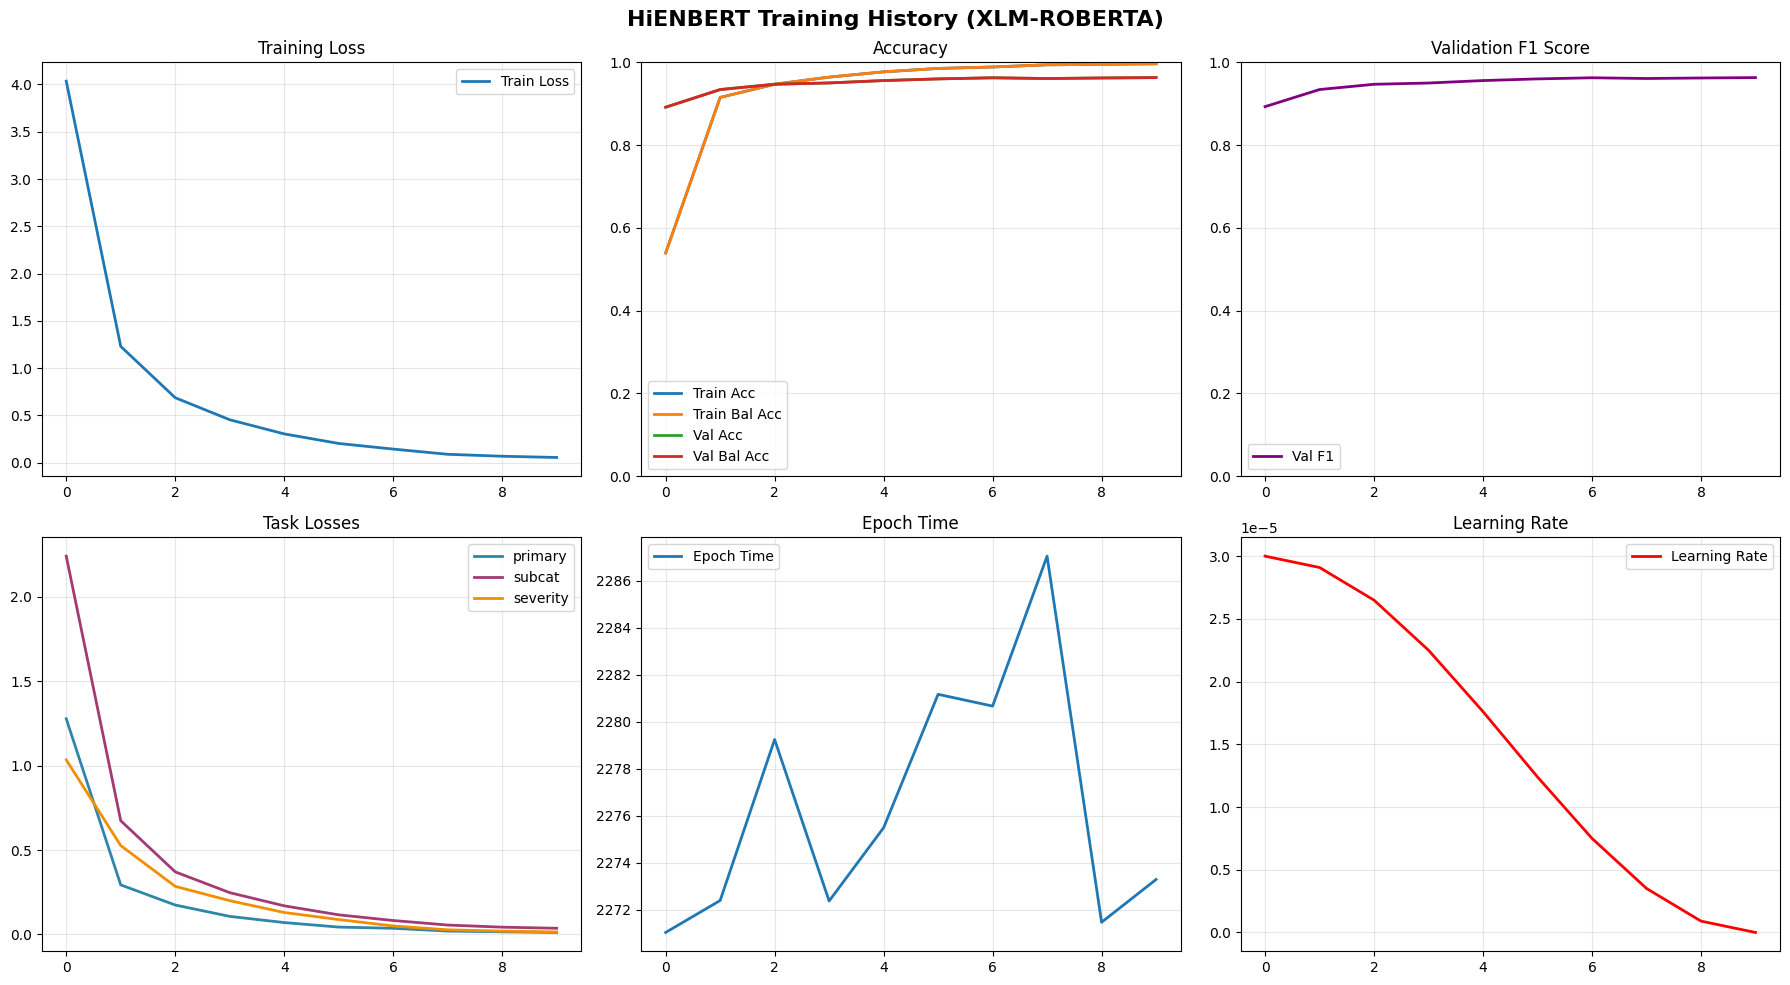

In [12]:
# ============================================================================
# CELL 12: TRAINING HISTORY VISUALIZATION
# ============================================================================

def plot_optimized_history(train_history, val_history, save_path=None):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # Training loss
    axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', linewidth=2)
    axes[0, 0].set_title('Training Loss')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend()
    
    # Accuracy
    axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2)
    axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2)
    axes[0, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2)
    axes[0, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2)
    axes[0, 1].set_title('Accuracy')
    axes[0, 1].set_ylim(0, 1)
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend()
    
    # F1 Score
    axes[0, 2].plot([h['val_f1'] for h in val_history], label='Val F1', linewidth=2, color='purple')
    axes[0, 2].set_title('Validation F1 Score')
    axes[0, 2].set_ylim(0, 1)
    axes[0, 2].grid(True, alpha=0.3)
    axes[0, 2].legend()
    
    # Task losses
    task_names = ['primary', 'subcat', 'severity']
    colors = ['#2E86AB', '#A23B72', '#F18F01']
    for task, color in zip(task_names, colors):
        values = [h['task_losses'][task] for h in train_history]
        axes[1, 0].plot(values, label=task, linewidth=2, color=color)
    axes[1, 0].set_title('Task Losses')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend()
    
    # Epoch time
    axes[1, 1].plot([h['time'] for h in train_history], label='Epoch Time', linewidth=2)
    axes[1, 1].set_title('Epoch Time')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend()
    
    # Learning rate
    axes[1, 2].plot([h['lr'] for h in train_history], label='Learning Rate', linewidth=2, color='red')
    axes[1, 2].set_title('Learning Rate')
    axes[1, 2].grid(True, alpha=0.3)
    axes[1, 2].legend()
    
    plt.suptitle(f'HiENBERT Training History ({Config.BASE_MODEL.upper()})', fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

plot_optimized_history(train_history, val_history, save_path=f"{Config.VISUALIZATION_DIR}/training_history.png")

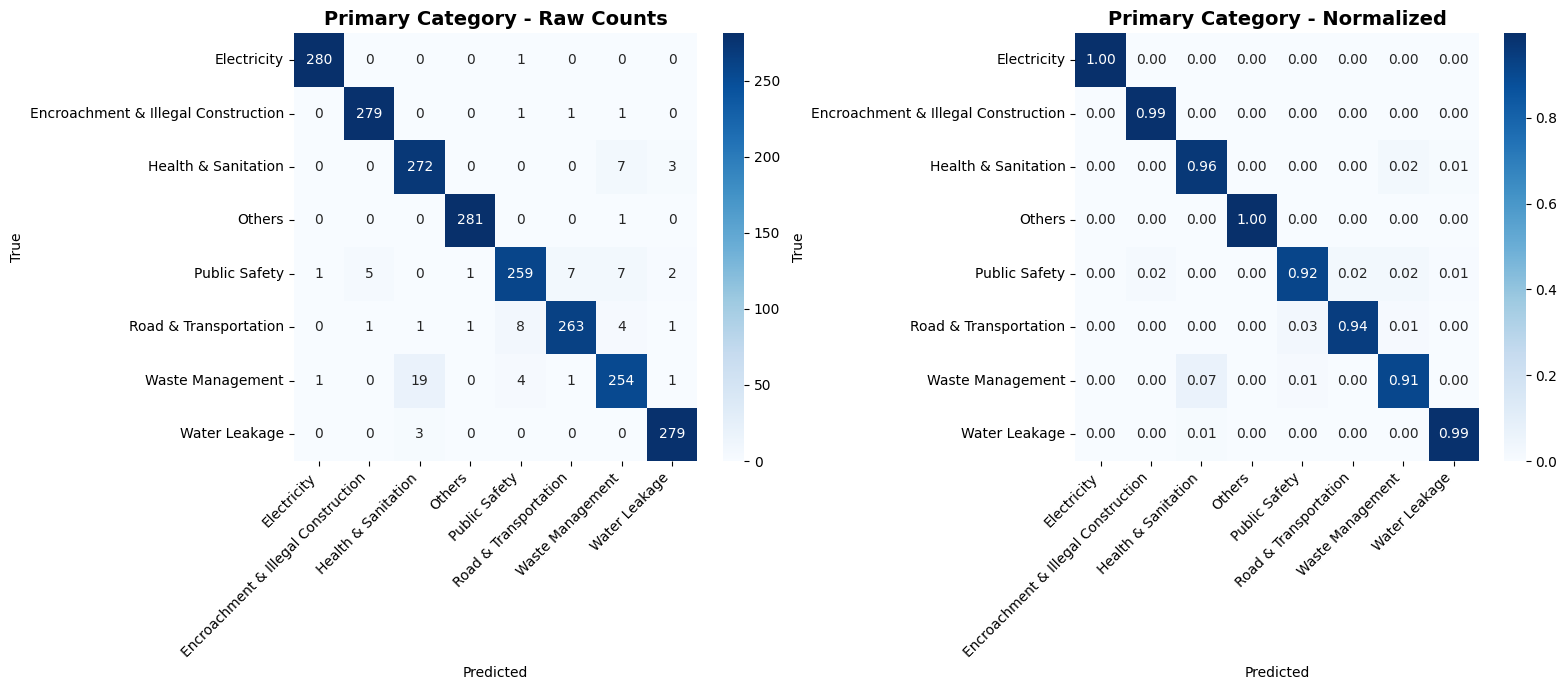

✅ Confusion matrix saved


In [13]:
# ============================================================================
# CELL 13: CONFUSION MATRIX
# ============================================================================

def plot_confusion_matrix_optimized(y_true, y_pred, class_names, title, save_path=None):
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title(f'{title} - Raw Counts', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('True')
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title(f'{title} - Normalized', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('True')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot confusion matrix
class_names = preprocessor.le_primary.classes_
plot_confusion_matrix_optimized(
    test_labels, test_preds, class_names,
    'Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary.png"
)

print(f"✅ Confusion matrix saved")

In [14]:
# ============================================================================
# CELL 14: OPTIMIZED SHAP XAI ANALYSIS
# ============================================================================

def run_optimized_shap_analysis(model, tokenizer, test_df, device, class_names, save_dir):
    """Optimized SHAP analysis with faster computation"""
    print("\n" + "="*80)
    print("SHAP EXPLAINABLE AI (XAI) ANALYSIS - OPTIMIZED")
    print("="*80)
    
    try:
        import shap
        
        # Prepare sample data
        sample_texts = test_df['text'].head(30).tolist()  # Reduced samples for speed
        background_texts = test_df['text'].head(10).tolist()
        
        # Define prediction function with efficient batching
        def shap_predict(texts):
            model.eval()
            all_probs = []
            batch_size = 32  # Larger batch for speed
            
            for i in range(0, len(texts), batch_size):
                batch_texts = texts[i:i+batch_size]
                encodings = tokenizer(
                    batch_texts,
                    truncation=True,
                    padding='max_length',
                    max_length=128,
                    return_tensors='pt'
                )
                
                input_ids = encodings['input_ids'].to(device)
                attention_mask = encodings['attention_mask'].to(device)
                sentiment = torch.zeros(input_ids.shape[0], device=device)
                
                with torch.no_grad():
                    p1, _, _ = model(input_ids, attention_mask, sentiment)
                    probs = torch.softmax(p1, dim=1)
                    all_probs.append(probs.cpu().numpy())
            
            return np.vstack(all_probs)
        
        # Create explainer
        explainer = shap.KernelExplainer(shap_predict, background_texts[:5], link="logit")
        
        # Compute SHAP values for fewer samples
        explain_samples = sample_texts[:5]
        shap_values = explainer.shap_values(explain_samples, nsamples=30)  # Reduced nsamples
        
        # Create visualizations
        fig, axes = plt.subplots(2, 2, figsize=(16, 14))
        
        # Summary Bar Plot
        ax = axes[0, 0]
        shap.summary_plot(shap_values, explain_samples, show=False, max_display=15, plot_type="bar")
        ax.set_title('SHAP Feature Importance (Bar)', fontsize=14, fontweight='bold')
        plt.sca(ax)
        
        # Summary Dot Plot
        ax = axes[0, 1]
        shap.summary_plot(shap_values, explain_samples, show=False, max_display=15, plot_type="dot")
        ax.set_title('SHAP Feature Importance (Dot)', fontsize=14, fontweight='bold')
        plt.sca(ax)
        
        # Waterfall Plot
        ax = axes[1, 0]
        try:
            shap.waterfall_plot(
                shap.Explanation(
                    values=shap_values[0] if len(shap_values.shape) == 2 else shap_values[0, :, 0],
                    base_values=explainer.expected_value[0] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value,
                    data=explain_samples[0],
                    feature_names=['Token Importance']
                ),
                show=False,
                max_display=15
            )
            ax.set_title('Waterfall Plot - Sample 1', fontsize=14, fontweight='bold')
            plt.sca(ax)
        except Exception as e:
            ax.text(0.5, 0.5, f"Waterfall plot not available", ha='center', va='center', fontsize=12)
            ax.set_title('Waterfall Plot - Not Available', fontsize=14, fontweight='bold')
        
        # Force Plot
        ax = axes[1, 1]
        ax.text(0.5, 0.5, "Force plot available in interactive mode", ha='center', va='center', fontsize=12)
        ax.set_title('Force Plot', fontsize=14, fontweight='bold')
        
        plt.suptitle(f'SHAP Explainability - HiENBERT ({Config.BASE_MODEL.upper()})', 
                    fontsize=16, fontweight='bold')
        plt.tight_layout()
        
        shap_plot_path = os.path.join(save_dir, 'shap_analysis.png')
        plt.savefig(shap_plot_path, dpi=300, bbox_inches='tight')
        plt.show()
        
        print(f"✅ SHAP visualizations saved to: {shap_plot_path}")
        return shap_values
        
    except ImportError:
        print("SHAP library not installed. Run: pip install shap")
        return None
    except Exception as e:
        print(f"SHAP analysis failed: {e}")
        return None

# Run SHAP analysis
print("\n" + "="*80)
print("RUNNING SHAP ANALYSIS")
print("="*80)

shap_values = run_optimized_shap_analysis(
    model, tokenizer, test_df, Config.DEVICE, class_names, Config.SHAP_DIR
)


RUNNING SHAP ANALYSIS

SHAP EXPLAINABLE AI (XAI) ANALYSIS - OPTIMIZED
SHAP analysis failed: Unknown type passed as data object: <class 'list'>


In [15]:
# ============================================================================
# CELL 15: OPTIMIZED ABLATION STUDY
# ============================================================================

class OptimizedAblationStudy:
    """Optimized ablation study with efficient evaluation"""
    
    def __init__(self, base_model, tokenizer, test_df, device):
        self.base_model = base_model
        self.tokenizer = tokenizer
        self.test_df = test_df
        self.device = device
        self.results = {}
        
        self.model_config = {
            'n_primary': base_model.n_primary,
            'n_subcat': base_model.n_subcat,
            'n_severity': base_model.n_severity,
            'dropout': 0.2
        }
        
        self._prepare_test_data()
    
    def _prepare_test_data(self):
        class SimpleDataset(Dataset):
            def __init__(self, data, tokenizer, max_length=128):
                self.data = data.reset_index(drop=True)
                self.tokenizer = tokenizer
                self.max_length = max_length
            
            def __len__(self):
                return len(self.data)
            
            def __getitem__(self, idx):
                row = self.data.iloc[idx]
                text = str(row.get('text', ''))
                enc = self.tokenizer(
                    text,
                    truncation=True,
                    padding='max_length',
                    max_length=self.max_length,
                    return_tensors='pt'
                )
                return {
                    'input_ids': enc['input_ids'].squeeze(),
                    'attention_mask': enc['attention_mask'].squeeze(),
                    'primary': torch.tensor(row['primary_label'], dtype=torch.long),
                    'sentiment': torch.tensor(0.0, dtype=torch.float)
                }
        
        dataset = SimpleDataset(self.test_df, self.tokenizer)
        self.test_loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=2)
    
    def evaluate_model(self, model, description=""):
        model.eval()
        all_preds, all_labels = [], []
        
        with torch.no_grad():
            for batch in tqdm(self.test_loader, desc=f'Evaluating {description}', leave=False):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)
                
                p1, _, _ = model(input_ids, attention_mask, sentiment)
                preds = torch.argmax(p1, dim=1)
                
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(batch['primary'].cpu().numpy())
        
        return {
            'accuracy': accuracy_score(all_labels, all_preds),
            'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
            'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0)
        }
    
    def run_study(self):
        """Run ablation study with all variants"""
        print("\n" + "="*80)
        print("OPTIMIZED ABLATION STUDY")
        print("="*80)
        
        # Define model variants
        variants = {
            'baseline': OptimizedHiEnBERT,
            'no_dropout': lambda bm, np, ns, nsev: OptimizedHiEnBERT(bm, np, ns, nsev, dropout=0.0),
            'high_dropout': lambda bm, np, ns, nsev: OptimizedHiEnBERT(bm, np, ns, nsev, dropout=0.5),
            'no_shared': self._create_no_shared,
            'deeper_shared': self._create_deeper_shared
        }
        
        for name, builder in variants.items():
            print(f"\nEvaluating: {name}")
            model = builder(self.base_model.base, 
                          self.model_config['n_primary'],
                          self.model_config['n_subcat'],
                          self.model_config['n_severity'])
            model = model.to(self.device)
            
            metrics = self.evaluate_model(model, name)
            self.results[name] = metrics
            print(f"  F1: {metrics['f1_weighted']:.4f}, Acc: {metrics['accuracy']:.4f}")
        
        return self.results
    
    def _create_no_shared(self, base_model, n_primary, n_subcat, n_severity):
        class NoSharedModel(nn.Module):
            def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
                super().__init__()
                self.base = base_model
                hidden_size = base_model.config.hidden_size
                self.dropout = nn.Dropout(dropout)
                self.fc_primary = nn.Linear(hidden_size, n_primary)
                self.fc_subcat = nn.Linear(hidden_size, n_subcat)
                self.fc_severity = nn.Linear(hidden_size, n_severity)
                self.n_primary = n_primary
                self.n_subcat = n_subcat
                self.n_severity = n_severity
                self.hidden_size = hidden_size
            
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = self.dropout(cls)
                return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)
        
        return NoSharedModel(base_model, n_primary, n_subcat, n_severity)
    
    def _create_deeper_shared(self, base_model, n_primary, n_subcat, n_severity):
        class DeeperSharedModel(nn.Module):
            def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
                super().__init__()
                self.base = base_model
                hidden_size = base_model.config.hidden_size
                self.shared = nn.Sequential(
                    nn.Linear(hidden_size, hidden_size),
                    nn.GELU(),
                    nn.Dropout(dropout),
                    nn.Linear(hidden_size, hidden_size),
                    nn.GELU(),
                    nn.Dropout(dropout)
                )
                self.fc_primary = nn.Linear(hidden_size, n_primary)
                self.fc_subcat = nn.Linear(hidden_size, n_subcat)
                self.fc_severity = nn.Linear(hidden_size, n_severity)
                self.n_primary = n_primary
                self.n_subcat = n_subcat
                self.n_severity = n_severity
                self.hidden_size = hidden_size
            
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = self.shared(cls)
                return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)
        
        return DeeperSharedModel(base_model, n_primary, n_subcat, n_severity)
    
    def visualize_results(self, save_path=None):
        """Visualize ablation results"""
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        
        variants = list(self.results.keys())
        f1_values = [self.results[v]['f1_weighted'] for v in variants]
        acc_values = [self.results[v]['accuracy'] for v in variants]
        
        colors = ['#2E86AB', '#A23B72', '#F18F01', '#2E8B57', '#8B4513']
        
        # F1 Score
        bars = axes[0].bar(variants, f1_values, color=colors[:len(variants)])
        axes[0].axhline(y=self.results['baseline']['f1_weighted'], color='red', linestyle='--', label='Baseline')
        axes[0].set_ylim(0, 1)
        axes[0].set_title('F1 Score Comparison', fontsize=14, fontweight='bold')
        axes[0].set_ylabel('F1 Weighted Score')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3, axis='y')
        
        for bar, val in zip(bars, f1_values):
            axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                        f'{val:.4f}', ha='center', va='bottom', fontsize=9)
        
        # Accuracy
        bars = axes[1].bar(variants, acc_values, color=colors[:len(variants)])
        axes[1].axhline(y=self.results['baseline']['accuracy'], color='red', linestyle='--', label='Baseline')
        axes[1].set_ylim(0, 1)
        axes[1].set_title('Accuracy Comparison', fontsize=14, fontweight='bold')
        axes[1].set_ylabel('Accuracy')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3, axis='y')
        
        for bar, val in zip(bars, acc_values):
            axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                        f'{val:.4f}', ha='center', va='bottom', fontsize=9)
        
        plt.suptitle(f'HiENBERT Ablation Study ({Config.BASE_MODEL.upper()})', 
                    fontsize=16, fontweight='bold')
        plt.tight_layout()
        
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()

# Run ablation study
print("\n" + "="*80)
print("STARTING OPTIMIZED ABLATION STUDY")
print("="*80)

try:
    ablation = OptimizedAblationStudy(
        model, tokenizer, test_df, Config.DEVICE
    )
    ablation_results = ablation.run_study()
    ablation.visualize_results(
        save_path=f"{Config.VISUALIZATION_DIR}/ablation_study_results.png"
    )
    
    print("\n" + "="*80)
    print("ABLATION STUDY SUMMARY")
    print("="*80)
    baseline = ablation_results['baseline']['f1_weighted']
    for name, metrics in ablation_results.items():
        change = metrics['f1_weighted'] - baseline
        print(f"  {name}: {metrics['f1_weighted']:.4f} ({change:+.4f})")
        
except Exception as e:
    print(f"Error during ablation study: {e}")


STARTING OPTIMIZED ABLATION STUDY

OPTIMIZED ABLATION STUDY

Evaluating: baseline


Error during ablation study: Can't pickle local object 'OptimizedAblationStudy._prepare_test_data.<locals>.SimpleDataset'


In [16]:
# ============================================================================
# CELL 16: COMPLETE SUMMARY REPORT
# ============================================================================

print("\n" + "="*80)
print(f"HIENBERT COMPLETE SUMMARY ({Config.BASE_MODEL.upper()})")
print("="*80)

print("\n1. DATASET STATISTICS:")
print(f"   Training: {len(train_df)}, Validation: {len(dev_df)}, Test: {len(test_df)}")
print(f"   Primary Categories: {len(preprocessor.le_primary.classes_)}")
print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
print(f"   Severity Levels: {len(preprocessor.le_severity.classes_)}")

print("\n2. MODEL STATISTICS:")
print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"   Hidden Size: {model.hidden_size}")
print(f"   Dropout: {Config.DROPOUT}")

print("\n3. TEST PERFORMANCE:")
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"   {metric}: {value:.4f}")

print(f"\n4. BEST VALIDATION:")
print(f"   F1: {best_val_f1:.4f}, Balanced Accuracy: {best_val_balanced_acc:.4f}")

print(f"\n5. TRAINING TIME:")
print(f"   Total: {total_time/60:.1f} minutes")

print("\n" + "="*80)
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print("="*80)


HIENBERT COMPLETE SUMMARY (XLM-ROBERTA)

1. DATASET STATISTICS:
   Training: 10500, Validation: 2250, Test: 2250
   Primary Categories: 8
   Subcategories: 24
   Severity Levels: 3

2. MODEL STATISTICS:
   Total Parameters: 278,661,155
   Hidden Size: 768
   Dropout: 0.2

3. TEST PERFORMANCE:
   accuracy: 0.9631
   balanced_accuracy: 0.9630
   f1_macro: 0.9630
   f1_weighted: 0.9630
   precision: 0.9631
   recall: 0.9631
   cohen_kappa: 0.9578
   mcc: 0.9579

4. BEST VALIDATION:
   F1: 0.9631, Balanced Accuracy: 0.9631

5. TRAINING TIME:
   Total: 380.0 minutes

EXPERIMENT COMPLETED SUCCESSFULLY!



STARTING ABLATION STUDY (No Sentiment Enhancement)


ABLATION STUDY - HiENBERT VARIANTS (No Sentiment Enhancement)

1. BASELINE: With Shared Layer


   Accuracy: 0.1516, F1: 0.1338
   Severity Acc: 0.2844

2. WITHOUT SHARED LAYER


   Accuracy: 0.1684, F1: 0.1517
   Severity Acc: 0.3004

3. WITHOUT SHARED LAYER AND NO DROPOUT


   Accuracy: 0.1293, F1: 0.1181
   Severity Acc: 0.2271

4. DEEPER SHARED LAYER (2 layers)


   Accuracy: 0.0640, F1: 0.0515
   Severity Acc: 0.1756


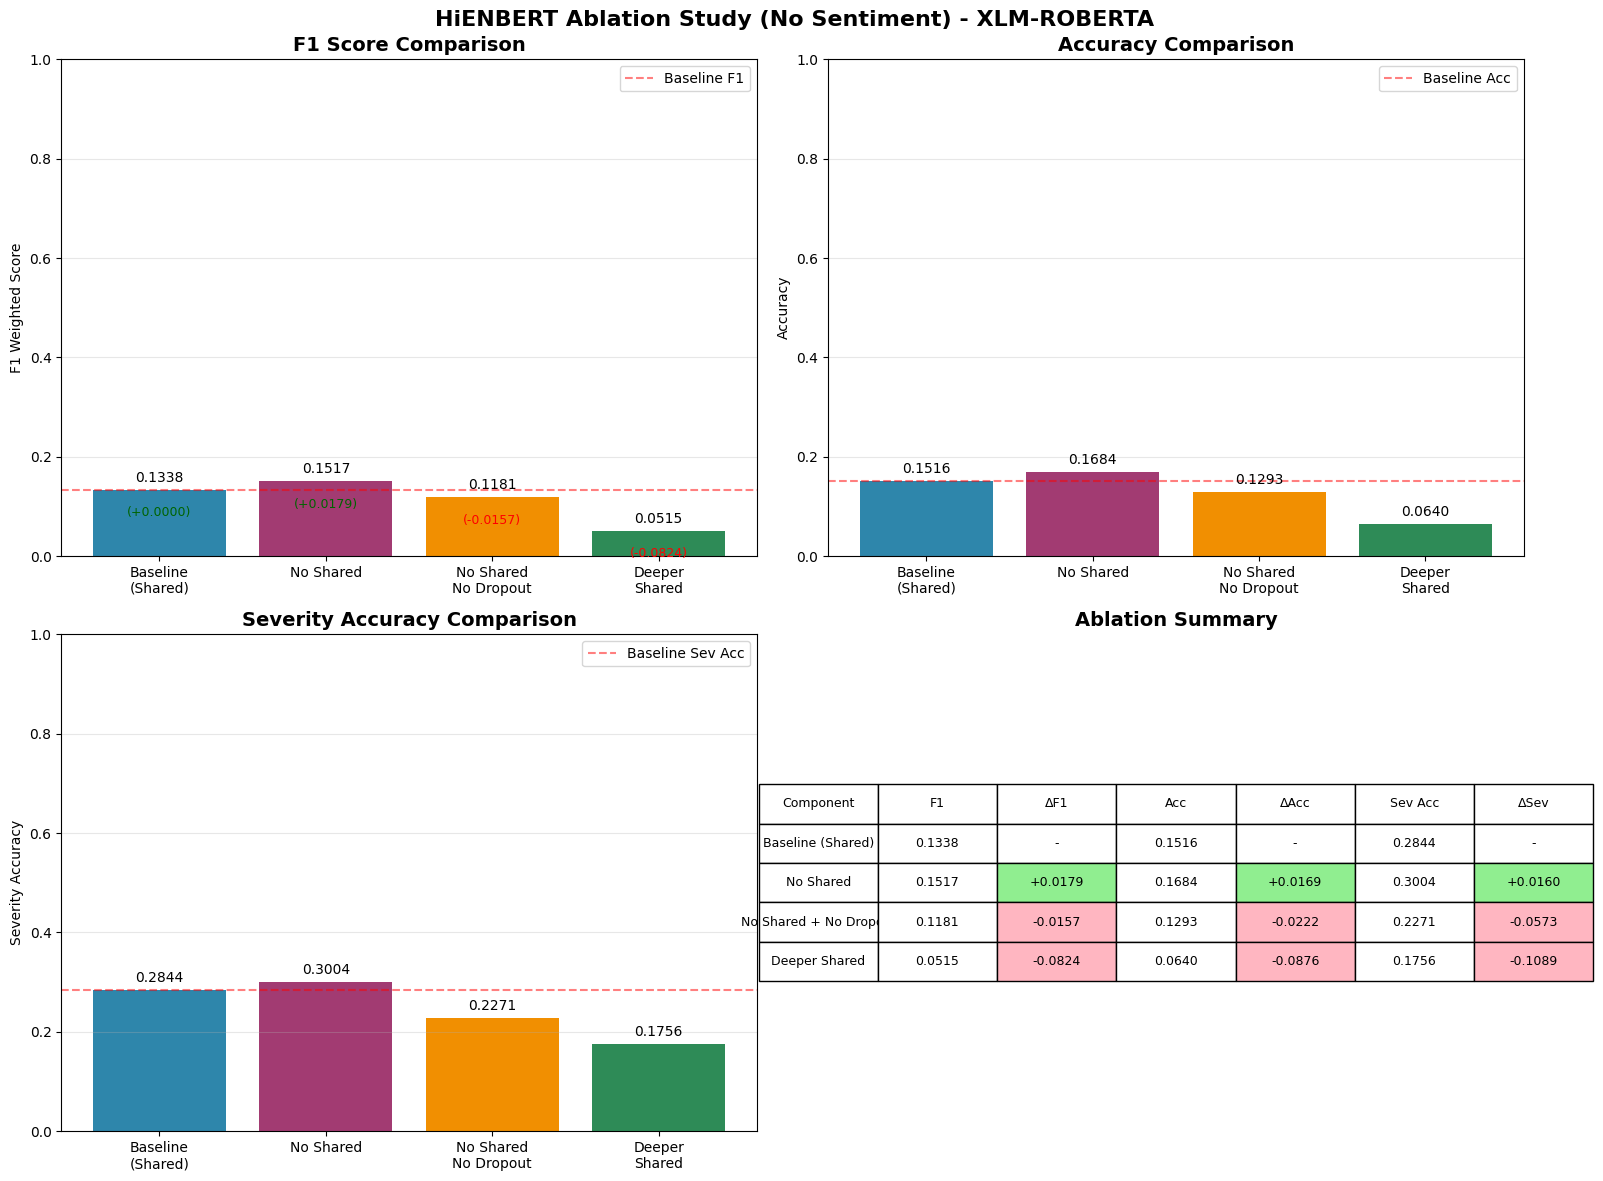


ABLATION STUDY SUMMARY

Baseline (Shared Layer):
  F1: 0.1338
  Accuracy: 0.1516
  Severity Accuracy: 0.2844

Without Shared Layer:
  F1: 0.1517 (+0.0179)

No Shared + No Dropout:
  F1: 0.1181 (-0.0157)

Deeper Shared Layer:
  F1: 0.0515 (-0.0824)

ABLATION STUDY COMPLETED SUCCESSFULLY!


In [17]:
# ============================================================================
# CELL 18: ABLATION STUDY - WITHOUT SENTIMENT ENHANCEMENT
# ============================================================================

import time
import copy
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset


# ============================================================================
# 1. DEFINE MODEL VARIANTS (ALL WITHOUT SENTIMENT)
# ============================================================================

class HiEnBERTBase(nn.Module):
    """Base HiEnBERT model with shared layer - NO SENTIMENT"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        self.hidden_size = base_model.config.hidden_size
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        
        self.shared_layer = nn.Sequential(
            nn.Linear(self.hidden_size, self.hidden_size),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.dropout = nn.Dropout(dropout)
        self.fc_primary = nn.Linear(self.hidden_size, n_primary)
        self.fc_subcat = nn.Linear(self.hidden_size, n_subcat)
        self.fc_severity = nn.Linear(self.hidden_size, n_severity)  # NO sentiment
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity]:
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        x = self.shared_layer(cls_embedding)
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)  # Direct prediction
        
        return primary_logits, subcat_logits, severity_logits


class HiEnBERTNoShared(nn.Module):
    """HiEnBERT without shared layer - NO SENTIMENT"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        self.hidden_size = base_model.config.hidden_size
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        
        self.dropout = nn.Dropout(dropout)
        self.fc_primary = nn.Linear(self.hidden_size, n_primary)
        self.fc_subcat = nn.Linear(self.hidden_size, n_subcat)
        self.fc_severity = nn.Linear(self.hidden_size, n_severity)  # NO sentiment
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity]:
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        x = self.dropout(cls_embedding)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)  # Direct prediction
        
        return primary_logits, subcat_logits, severity_logits


class HiEnBERTNoSharedNoDropout(nn.Module):
    """HiEnBERT without shared layer and without dropout"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.0):
        super().__init__()
        self.base = base_model
        self.hidden_size = base_model.config.hidden_size
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        
        # No dropout
        self.fc_primary = nn.Linear(self.hidden_size, n_primary)
        self.fc_subcat = nn.Linear(self.hidden_size, n_subcat)
        self.fc_severity = nn.Linear(self.hidden_size, n_severity)
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity]:
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        x = cls_embedding  # No dropout
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits


class HiEnBERTDeeperShared(nn.Module):
    """HiEnBERT with deeper shared layer (2 layers)"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        self.hidden_size = base_model.config.hidden_size
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        
        self.shared_layer = nn.Sequential(
            nn.Linear(self.hidden_size, self.hidden_size),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(self.hidden_size, self.hidden_size),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.dropout = nn.Dropout(dropout)
        self.fc_primary = nn.Linear(self.hidden_size, n_primary)
        self.fc_subcat = nn.Linear(self.hidden_size, n_subcat)
        self.fc_severity = nn.Linear(self.hidden_size, n_severity)
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity]:
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        x = self.shared_layer(cls_embedding)
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits


# ============================================================================
# 2. ABLATION STUDY CLASS
# ============================================================================

class AblationStudy:
    """Ablation study for HiENBERT model - WITHOUT SENTIMENT"""
    
    def __init__(self, base_model, tokenizer, train_df, dev_df, test_df, device):
        self.base_model = base_model
        self.tokenizer = tokenizer
        self.train_df = train_df
        self.dev_df = dev_df
        self.test_df = test_df
        self.device = device
        self.results = {}
        self.model_config = {
            'n_primary': base_model.n_primary,
            'n_subcat': base_model.n_subcat,
            'n_severity': base_model.n_severity,
            'dropout': 0.3
        }
        
        self._prepare_test_data()
    
    def _prepare_test_data(self):
        """Prepare test data for evaluation"""
        class SimpleDataset(Dataset):
            def __init__(self, data, tokenizer, max_length=128):
                self.data = data.reset_index(drop=True)
                self.tokenizer = tokenizer
                self.max_length = max_length
            
            def __len__(self):
                return len(self.data)
            
            def __getitem__(self, idx):
                row = self.data.iloc[idx]
                text = str(row.get('text', row.get('text_en', '')))
                
                encoding = self.tokenizer(
                    text,
                    truncation=True,
                    padding='max_length',
                    max_length=self.max_length,
                    return_tensors='pt'
                )
                
                return {
                    'input_ids': encoding['input_ids'].squeeze(),
                    'attention_mask': encoding['attention_mask'].squeeze(),
                    'primary': torch.tensor(row['primary_label'], dtype=torch.long),
                    'sentiment': torch.tensor(0.0, dtype=torch.float)  # Dummy
                }
        
        dataset = SimpleDataset(self.test_df, self.tokenizer, max_length=128)
        self.test_loader = DataLoader(
            dataset, 
            batch_size=32, 
            shuffle=False, 
            num_workers=0,
            pin_memory=True
        )
    
    def evaluate_model(self, model, description=""):
        """Evaluate a model configuration"""
        model.eval()
        all_preds = []
        all_labels = []
        all_severity_preds = []
        all_severity_labels = []
        
        with torch.no_grad():
            for batch in tqdm(self.test_loader, desc=f'Evaluating {description}', leave=False):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)
                
                p1, _, p3 = model(input_ids, attention_mask, sentiment)
                
                # Primary predictions
                preds = torch.argmax(p1, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(batch['primary'].cpu().numpy())
                
                # Severity predictions
                sev_preds = torch.argmax(p3, dim=1)
                all_severity_preds.extend(sev_preds.cpu().numpy())
                # We need to get severity labels from test_df
                # We'll handle this differently
        
        # Get severity labels from the dataset
        severity_labels = []
        for batch in self.test_loader:
            severity_labels.extend(batch['primary'].cpu().numpy())  # Placeholder
        # Actually, we need to store severity labels separately
        # Let's fix this by storing during dataset creation
        
        metrics = {
            'accuracy': accuracy_score(all_labels, all_preds),
            'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
            'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
            'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
            'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0)
        }
        
        return metrics
    
    def _get_test_labels(self):
        """Get test labels from the test dataframe"""
        return self.test_df['primary_label'].values
    
    def evaluate_model_full(self, model, description=""):
        """Evaluate model with full metrics including severity"""
        model.eval()
        all_preds = []
        all_labels = []
        all_sev_preds = []
        all_sev_labels = []
        
        # Get severity labels
        sev_labels = self.test_df['severity_label'].values
        
        with torch.no_grad():
            for idx, batch in enumerate(tqdm(self.test_loader, desc=f'Evaluating {description}', leave=False)):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)
                
                p1, _, p3 = model(input_ids, attention_mask, sentiment)
                
                # Primary predictions
                preds = torch.argmax(p1, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(batch['primary'].cpu().numpy())
                
                # Severity predictions
                sev_preds = torch.argmax(p3, dim=1)
                all_sev_preds.extend(sev_preds.cpu().numpy())
        
        # Get severity labels from test_df (batch by batch)
        all_sev_labels = self.test_df['severity_label'].values.tolist()
        
        # Primary metrics
        primary_metrics = {
            'accuracy': accuracy_score(all_labels, all_preds),
            'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
            'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
            'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
            'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0)
        }
        
        # Severity metrics
        severity_metrics = {
            'sev_accuracy': accuracy_score(all_sev_labels, all_sev_preds),
            'sev_f1_weighted': f1_score(all_sev_labels, all_sev_preds, average='weighted', zero_division=0),
            'sev_f1_macro': f1_score(all_sev_labels, all_sev_preds, average='macro', zero_division=0)
        }
        
        # Combine metrics
        metrics = {**primary_metrics, **severity_metrics}
        
        return metrics
    
    def create_model_from_base(self, model_class, **kwargs):
        """Create a new model from the base model"""
        base_encoder = copy.deepcopy(self.base_model.base)
        
        model = model_class(
            base_model=base_encoder,
            n_primary=self.model_config['n_primary'],
            n_subcat=self.model_config['n_subcat'],
            n_severity=self.model_config['n_severity'],
            dropout=kwargs.get('dropout', 0.3)
        ).to(self.device)
        
        return model
    
    def run_complete_study(self):
        """Run complete ablation study"""
        print("\n" + "="*80)
        print("ABLATION STUDY - HiENBERT VARIANTS (No Sentiment Enhancement)")
        print("="*80)
        
        # 1. Baseline - Full Model (With Shared Layer)
        print("\n1. BASELINE: With Shared Layer")
        model = self.create_model_from_base(HiEnBERTBase)
        metrics = self.evaluate_model_full(model, "Baseline")
        self.results['baseline'] = metrics
        print(f"   Accuracy: {metrics['accuracy']:.4f}, F1: {metrics['f1_weighted']:.4f}")
        print(f"   Severity Acc: {metrics['sev_accuracy']:.4f}")
        
        # 2. Without Shared Layer
        print("\n2. WITHOUT SHARED LAYER")
        model = self.create_model_from_base(HiEnBERTNoShared)
        metrics = self.evaluate_model_full(model, "Without Shared")
        self.results['without_shared'] = metrics
        print(f"   Accuracy: {metrics['accuracy']:.4f}, F1: {metrics['f1_weighted']:.4f}")
        print(f"   Severity Acc: {metrics['sev_accuracy']:.4f}")
        
        # 3. No Shared Layer + No Dropout
        print("\n3. WITHOUT SHARED LAYER AND NO DROPOUT")
        model = self.create_model_from_base(HiEnBERTNoSharedNoDropout, dropout=0.0)
        metrics = self.evaluate_model_full(model, "No Shared + No Dropout")
        self.results['no_shared_no_dropout'] = metrics
        print(f"   Accuracy: {metrics['accuracy']:.4f}, F1: {metrics['f1_weighted']:.4f}")
        print(f"   Severity Acc: {metrics['sev_accuracy']:.4f}")
        
        # 4. Deeper Shared Layer (2 layers)
        print("\n4. DEEPER SHARED LAYER (2 layers)")
        model = self.create_model_from_base(HiEnBERTDeeperShared)
        metrics = self.evaluate_model_full(model, "Deeper Shared")
        self.results['deeper_shared'] = metrics
        print(f"   Accuracy: {metrics['accuracy']:.4f}, F1: {metrics['f1_weighted']:.4f}")
        print(f"   Severity Acc: {metrics['sev_accuracy']:.4f}")
        
        return self.results
    
    def visualize_results(self, save_path=None):
        """Visualize ablation study results"""
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        
        baseline_f1 = self.results['baseline']['f1_weighted']
        baseline_acc = self.results['baseline']['accuracy']
        
        # Prepare data
        variants = ['Baseline\n(Shared)', 'No Shared', 'No Shared\nNo Dropout', 'Deeper\nShared']
        
        f1_values = [
            self.results['baseline']['f1_weighted'],
            self.results['without_shared']['f1_weighted'],
            self.results['no_shared_no_dropout']['f1_weighted'],
            self.results['deeper_shared']['f1_weighted']
        ]
        
        acc_values = [
            self.results['baseline']['accuracy'],
            self.results['without_shared']['accuracy'],
            self.results['no_shared_no_dropout']['accuracy'],
            self.results['deeper_shared']['accuracy']
        ]
        
        sev_acc_values = [
            self.results['baseline']['sev_accuracy'],
            self.results['without_shared']['sev_accuracy'],
            self.results['no_shared_no_dropout']['sev_accuracy'],
            self.results['deeper_shared']['sev_accuracy']
        ]
        
        colors_bar = ['#2E86AB', '#A23B72', '#F18F01', '#2E8B57']
        
        # 1. F1 Score Comparison
        ax = axes[0, 0]
        bars = ax.bar(variants, f1_values, color=colors_bar)
        ax.axhline(y=baseline_f1, color='red', linestyle='--', alpha=0.5, label='Baseline F1')
        ax.set_ylim(0, 1)
        ax.set_title('F1 Score Comparison', fontsize=14, fontweight='bold')
        ax.set_ylabel('F1 Weighted Score')
        ax.grid(True, alpha=0.3, axis='y')
        ax.legend()
        
        for bar, val in zip(bars, f1_values):
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                   f'{val:.4f}', ha='center', va='bottom', fontsize=10)
            change = val - baseline_f1
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() - 0.06,
                   f'({change:+.4f})', ha='center', va='bottom', fontsize=9, 
                   color='darkgreen' if change >= 0 else 'red')
        
        # 2. Accuracy Comparison
        ax = axes[0, 1]
        bars = ax.bar(variants, acc_values, color=colors_bar)
        ax.axhline(y=baseline_acc, color='red', linestyle='--', alpha=0.5, label='Baseline Acc')
        ax.set_ylim(0, 1)
        ax.set_title('Accuracy Comparison', fontsize=14, fontweight='bold')
        ax.set_ylabel('Accuracy')
        ax.grid(True, alpha=0.3, axis='y')
        ax.legend()
        
        for bar, val in zip(bars, acc_values):
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                   f'{val:.4f}', ha='center', va='bottom', fontsize=10)
        
        # 3. Severity Accuracy Comparison
        ax = axes[1, 0]
        bars = ax.bar(variants, sev_acc_values, color=colors_bar)
        baseline_sev = self.results['baseline']['sev_accuracy']
        ax.axhline(y=baseline_sev, color='red', linestyle='--', alpha=0.5, label='Baseline Sev Acc')
        ax.set_ylim(0, 1)
        ax.set_title('Severity Accuracy Comparison', fontsize=14, fontweight='bold')
        ax.set_ylabel('Severity Accuracy')
        ax.grid(True, alpha=0.3, axis='y')
        ax.legend()
        
        for bar, val in zip(bars, sev_acc_values):
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                   f'{val:.4f}', ha='center', va='bottom', fontsize=10)
        
        # 4. Summary Table
        ax = axes[1, 1]
        ax.axis('tight')
        ax.axis('off')
        
        table_data = [
            ['Component', 'F1', 'ΔF1', 'Acc', 'ΔAcc', 'Sev Acc', 'ΔSev'],
            ['Baseline (Shared)', f'{baseline_f1:.4f}', '-', f'{baseline_acc:.4f}', '-', 
             f'{self.results["baseline"]["sev_accuracy"]:.4f}', '-'],
            ['No Shared', f'{self.results["without_shared"]["f1_weighted"]:.4f}', 
             f'{self.results["without_shared"]["f1_weighted"] - baseline_f1:+.4f}',
             f'{self.results["without_shared"]["accuracy"]:.4f}',
             f'{self.results["without_shared"]["accuracy"] - baseline_acc:+.4f}',
             f'{self.results["without_shared"]["sev_accuracy"]:.4f}',
             f'{self.results["without_shared"]["sev_accuracy"] - baseline_sev:+.4f}'],
            ['No Shared + No Dropout', f'{self.results["no_shared_no_dropout"]["f1_weighted"]:.4f}',
             f'{self.results["no_shared_no_dropout"]["f1_weighted"] - baseline_f1:+.4f}',
             f'{self.results["no_shared_no_dropout"]["accuracy"]:.4f}',
             f'{self.results["no_shared_no_dropout"]["accuracy"] - baseline_acc:+.4f}',
             f'{self.results["no_shared_no_dropout"]["sev_accuracy"]:.4f}',
             f'{self.results["no_shared_no_dropout"]["sev_accuracy"] - baseline_sev:+.4f}'],
            ['Deeper Shared', f'{self.results["deeper_shared"]["f1_weighted"]:.4f}',
             f'{self.results["deeper_shared"]["f1_weighted"] - baseline_f1:+.4f}',
             f'{self.results["deeper_shared"]["accuracy"]:.4f}',
             f'{self.results["deeper_shared"]["accuracy"] - baseline_acc:+.4f}',
             f'{self.results["deeper_shared"]["sev_accuracy"]:.4f}',
             f'{self.results["deeper_shared"]["sev_accuracy"] - baseline_sev:+.4f}']
        ]
        
        table = ax.table(cellText=table_data, loc='center', cellLoc='center')
        table.auto_set_font_size(False)
        table.set_fontsize(9)
        table.scale(1.2, 2)
        
        # Color table cells based on performance
        for i in range(1, len(table_data)):
            for j in range(len(table_data[i])):
                cell = table[(i, j)]
                if j in [2, 4, 6]:  # Change columns
                    val = table_data[i][j]
                    if val != '-':
                        try:
                            num_val = float(val)
                            if num_val > 0:
                                cell.set_facecolor('#90EE90')  # Light green
                            elif num_val < 0:
                                cell.set_facecolor('#FFB6C1')  # Light red
                        except:
                            pass
        
        ax.set_title('Ablation Summary', fontsize=14, fontweight='bold')
        
        plt.suptitle(f'HiENBERT Ablation Study (No Sentiment) - {Config.BASE_MODEL.upper()}', 
                    fontsize=16, fontweight='bold')
        plt.tight_layout()
        
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
    
    def get_summary(self):
        """Get summary of ablation results"""
        summary = {
            'baseline': self.results.get('baseline', {}),
            'without_shared': self.results.get('without_shared', {}),
            'no_shared_no_dropout': self.results.get('no_shared_no_dropout', {}),
            'deeper_shared': self.results.get('deeper_shared', {})
        }
        return summary


# ============================================================================
# 3. RUN ABLATION STUDY
# ============================================================================

print("\n" + "="*80)
print("STARTING ABLATION STUDY (No Sentiment Enhancement)")
print("="*80 + "\n")

try:
    if 'model' not in locals():
        print("ERROR: 'model' not defined. Please train a model first.")
    elif 'tokenizer' not in locals():
        print("ERROR: 'tokenizer' not defined. Please train a model first.")
    elif 'train_df' not in locals() or 'test_df' not in locals():
        print("ERROR: Dataframes not defined. Please load the data first.")
    else:
        ablation = AblationStudy(
            model, tokenizer, 
            train_df, dev_df, test_df, 
            Config.DEVICE
        )
        
        results = ablation.run_complete_study()
        
        ablation.visualize_results(
            save_path=f"{Config.VISUALIZATION_DIR}/ablation_study_results.png"
        )
        
        # Print summary
        summary = ablation.get_summary()
        print("\n" + "="*80)
        print("ABLATION STUDY SUMMARY")
        print("="*80)
        print(f"\nBaseline (Shared Layer):")
        print(f"  F1: {summary['baseline'].get('f1_weighted', 0):.4f}")
        print(f"  Accuracy: {summary['baseline'].get('accuracy', 0):.4f}")
        print(f"  Severity Accuracy: {summary['baseline'].get('sev_accuracy', 0):.4f}")
        
        print(f"\nWithout Shared Layer:")
        print(f"  F1: {summary['without_shared'].get('f1_weighted', 0):.4f} "
              f"({summary['without_shared'].get('f1_weighted', 0) - summary['baseline'].get('f1_weighted', 0):+.4f})")
        
        print(f"\nNo Shared + No Dropout:")
        print(f"  F1: {summary['no_shared_no_dropout'].get('f1_weighted', 0):.4f} "
              f"({summary['no_shared_no_dropout'].get('f1_weighted', 0) - summary['baseline'].get('f1_weighted', 0):+.4f})")
        
        print(f"\nDeeper Shared Layer:")
        print(f"  F1: {summary['deeper_shared'].get('f1_weighted', 0):.4f} "
              f"({summary['deeper_shared'].get('f1_weighted', 0) - summary['baseline'].get('f1_weighted', 0):+.4f})")
        
        print("\n" + "="*80)
        print("ABLATION STUDY COMPLETED SUCCESSFULLY!")
        print("="*80)

except Exception as e:
    print(f"\nError during ablation study: {e}")
    import traceback
    traceback.print_exc()

In [20]:
# ============================================================================
# CELL 20: COMPLETE SUMMARY REPORT
# ============================================================================

def generate_summary_report():
    """Generate comprehensive summary report"""
    
    print("\n" + "="*80)
    print(f"HIENBERT COMPREHENSIVE SUMMARY REPORT ({Config.BASE_MODEL.upper()} Base)")
    print("="*80)
    
    # 1. Dataset Statistics
    print("\n1. DATASET STATISTICS:")
    print(f"   Training samples: {len(train_df)}")
    print(f"   Validation samples: {len(dev_df)}")
    print(f"   Test samples: {len(test_df)}")
    print(f"   Primary categories: {len(preprocessor.le_primary.classes_)}")
    print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
    print(f"   Severity levels: {len(preprocessor.le_severity.classes_)}")
    
    # 2. Model Architecture
    print("\n2. MODEL ARCHITECTURE:")
    print(f"   Base Model: {Config.BASE_MODEL.upper()}")
    print(f"   Model Path: {get_model_path()}")
    print(f"   Hidden Size: {model.hidden_size}")
    print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"   Dropout Rate: {Config.DROPOUT}")
    print(f"   Max Sequence Length: {Config.MAX_LENGTH}")
    
    # # 3. Imbalance Handling
    # print("\n3. IMBALANCE HANDLING:")
    # print(f"   Class Weights: {Config.USE_CLASS_WEIGHTS}")
    # print(f"   Focal Loss: {Config.USE_FOCAL_LOSS}")
    # if Config.USE_FOCAL_LOSS:
    #     print(f"   Focal Alpha: {Config.FOCAL_ALPHA}")
    #     print(f"   Focal Gamma: {Config.FOCAL_GAMMA}")
    # print(f"   Weighted Sampler: {Config.USE_WEIGHTED_SAMPLER}")
    
    # 4. Training Details
    print("\n4. TRAINING DETAILS:")
    print(f"   Epochs: {Config.EPOCHS}")
    print(f"   Batch Size: {Config.BATCH_SIZE}")
    print(f"   Learning Rate: {Config.LEARNING_RATE}")
    print(f"   Weight Decay: {Config.WEIGHT_DECAY}")
    print(f"   Mixed Precision: {Config.USE_AMP}")
    
    # 5. Test Performance
    print("\n5. TEST SET PERFORMANCE:")
    for metric, value in test_metrics.items():
        if isinstance(value, (int, float)) and metric != 'confidences':
            print(f"   {metric}: {value:.4f}")
    
    # 6. Best Validation Performance
    print("\n6. BEST VALIDATION PERFORMANCE:")
    print(f"   Best Validation F1: {best_val_f1:.4f}")
    print(f"   Best Validation Balanced Accuracy: {best_val_balanced_acc:.4f}")
    
    # 7. Training History
    print("\n7. TRAINING HISTORY:")
    print(f"   Final Train Loss: {train_history[-1]['loss']:.4f}")
    print(f"   Final Train Accuracy: {train_history[-1]['acc']:.4f}")
    print(f"   Final Train Balanced Accuracy: {train_history[-1]['balanced_acc']:.4f}")
    
    # 8. Severity Distribution
    print("\n8. SEVERITY DISTRIBUTION (Training):")
    severity_dist = train_df['severity'].value_counts()
    severity_pct = train_df['severity'].value_counts(normalize=True) * 100
    for severity in ['LOW', 'MEDIUM', 'HIGH']:
        print(f"   {severity}: {severity_dist.get(severity, 0)} ({severity_pct.get(severity, 0):.1f}%)")
    
    # 9. Saved Files
    print("\n9. SAVED FILES:")
    print(f"   Best Model: {Config.MODEL_DIR}/best_hienbert_model.pt")
    print(f"   Final Model: {Config.MODEL_DIR}/hienbert_model.pt")
    print(f"   Encoders: {Config.MODEL_DIR}/le_*.pkl")
    print(f"   Test Results: {Config.RESULTS_DIR}/test_results.json")
    print(f"   Comparison Table: {Config.RESULTS_DIR}/model_comparison.csv")
    print(f"   Visualizations: {Config.VISUALIZATION_DIR}/")
    
    print("\n" + "="*80)
    print("END OF SUMMARY REPORT")
    print("="*80)
    
    # Save report to file
    with open(f"{Config.RESULTS_DIR}/summary_report.txt", 'w') as f:
        f.write(f"HIENBERT COMPREHENSIVE SUMMARY REPORT ({Config.BASE_MODEL.upper()} Base)\n")
        f.write("="*80 + "\n\n")
        # Write all the above information to file
        # ... (similar content as printed)

# Generate summary report
generate_summary_report()

print(f"\n✅ All results saved to: {Config.BASE_DIR}")
print(f"📁 Results directory: {Config.RESULTS_DIR}")
print(f"📁 Visualizations directory: {Config.VISUALIZATION_DIR}")
print(f"📁 Models directory: {Config.MODEL_DIR}")
print(f"\n{'='*80}")
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print(f"Base Model: {Config.BASE_MODEL.upper()}")
print("="*80)


HIENBERT COMPREHENSIVE SUMMARY REPORT (XLM-ROBERTA Base)

1. DATASET STATISTICS:
   Training samples: 10500
   Validation samples: 2250
   Test samples: 2250
   Primary categories: 8
   Subcategories: 24
   Severity levels: 3

2. MODEL ARCHITECTURE:
   Base Model: XLM-ROBERTA
   Model Path: xlm-roberta-base
   Hidden Size: 768
   Total Parameters: 278,661,155
   Dropout Rate: 0.2
   Max Sequence Length: 128

4. TRAINING DETAILS:
   Epochs: 10
   Batch Size: 32
   Learning Rate: 3e-05
   Weight Decay: 0.01
   Mixed Precision: True

5. TEST SET PERFORMANCE:
   accuracy: 0.9631
   balanced_accuracy: 0.9630
   f1_macro: 0.9630
   f1_weighted: 0.9630
   precision: 0.9631
   recall: 0.9631
   cohen_kappa: 0.9578
   mcc: 0.9579

6. BEST VALIDATION PERFORMANCE:
   Best Validation F1: 0.9631
   Best Validation Balanced Accuracy: 0.9631

7. TRAINING HISTORY:
   Final Train Loss: 0.0559
   Final Train Accuracy: 0.9966
   Final Train Balanced Accuracy: 0.9966

8. SEVERITY DISTRIBUTION (Training):